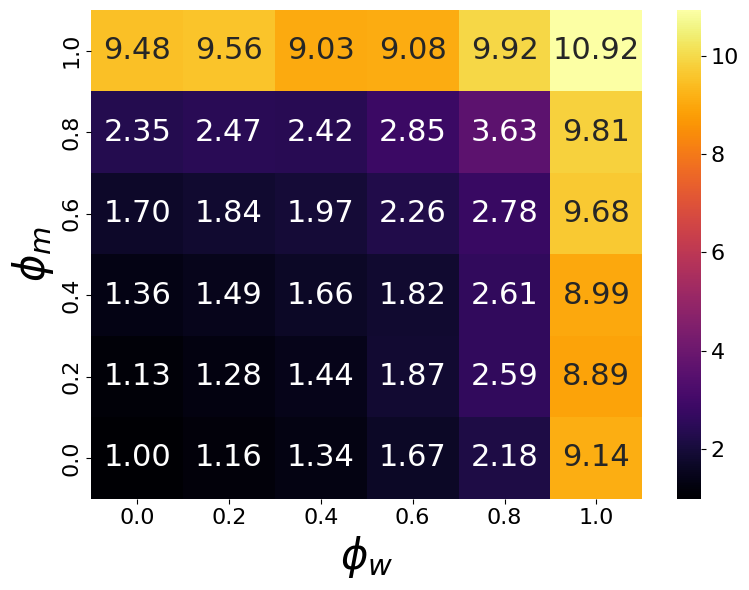

In [12]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("euclidean_mallows_accomplice.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails


# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["number_of_stable_matchings"].mean().reset_index()

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="number_of_stable_matchings")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="inferno", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("euclidean_mallows_lattice.pdf", format="pdf")
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_23638/1339008830.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['self_manipulating_women'] = pd.to_numeric(df_filtered['self_manipulating_women'], errors='coerce')


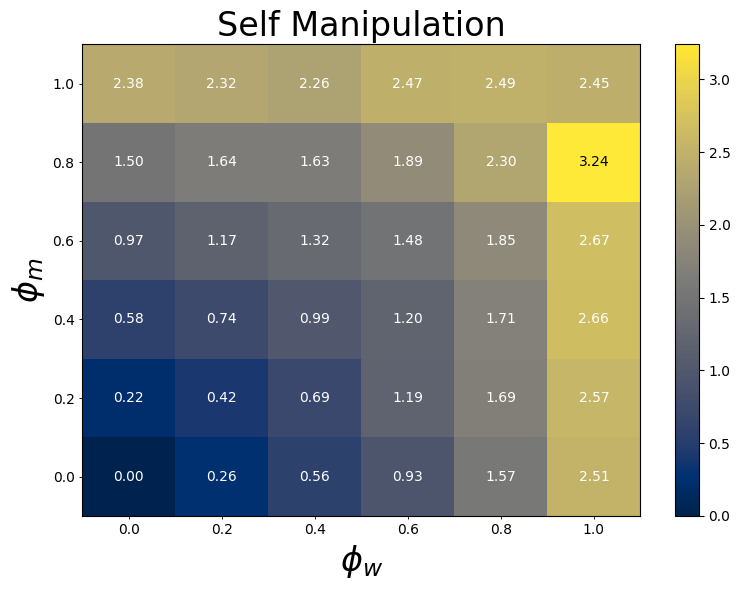

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("euclidean_mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'self_manipulating_women']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['self_manipulating_women'] = pd.to_numeric(df_filtered['self_manipulating_women'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['self_manipulating_women'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='self_manipulating_women', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='cividis', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            if i == 4 and j== 5:
                text_color = 'black'  # Special cell
            else:
                text_color = 'white'
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color=text_color)

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Self Manipulation', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("euclidean_mallows_self.pdf", format='pdf')
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_12247/3554979626.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')


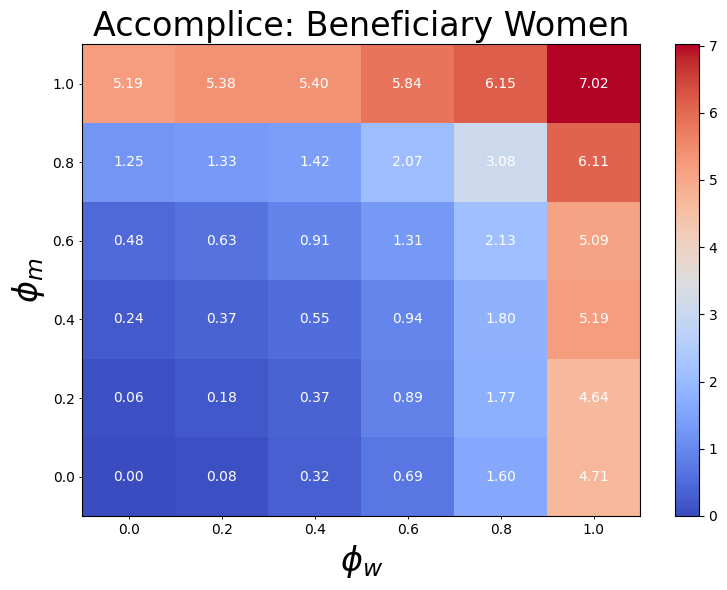

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("euclidean_mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'count_woman']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_woman'] = pd.to_numeric(df_filtered['count_woman'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_woman'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='count_woman', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

data_matrix = data_matrix / 30

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='coolwarm', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='white')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Accomplice: Beneficiary Women', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("euclidean_mallows_acc_women.pdf", format='pdf')
plt.show()


In [5]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


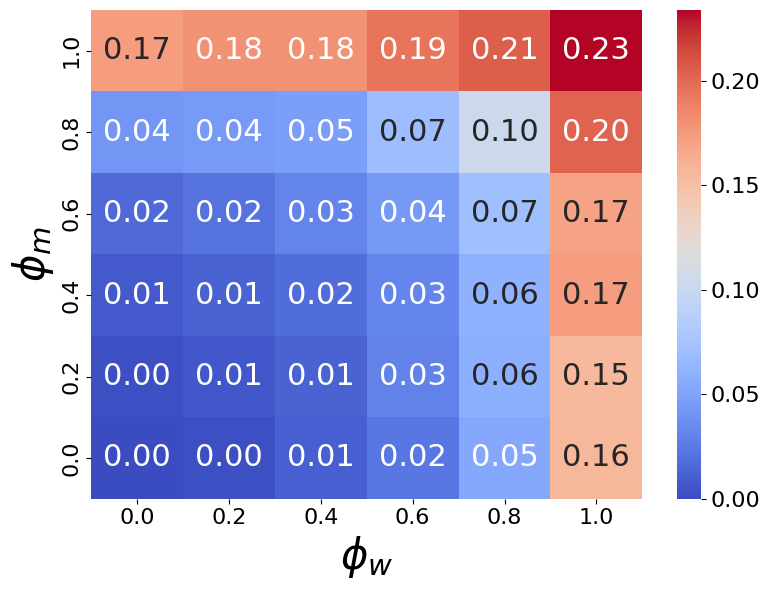

In [7]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("euclidean_mallows_accomplice.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["count_woman"].mean().reset_index()

heatmap_data["count_woman"] = heatmap_data["count_woman"] / 30

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="count_woman")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("euclidean_mallows_acc_women_30.pdf", format="pdf")
plt.show()


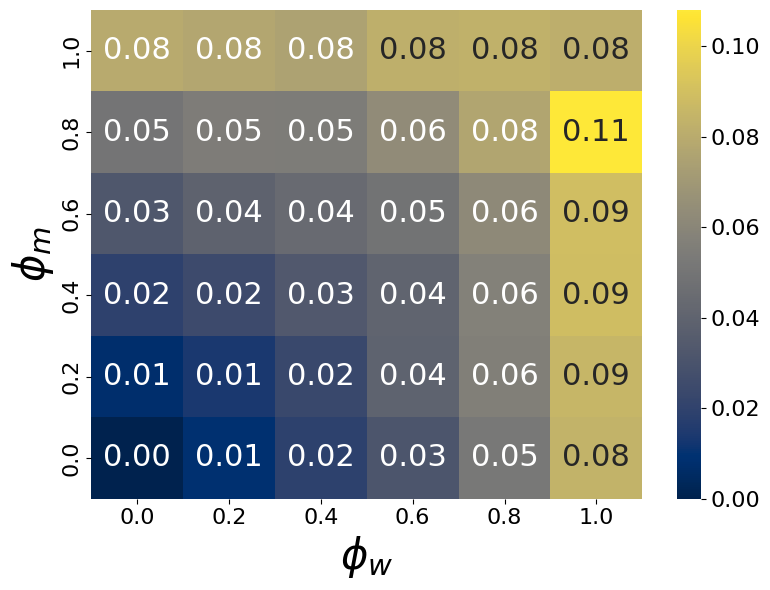

In [9]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("euclidean_mallows_accomplice.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["self_manipulating_women"].mean().reset_index()

heatmap_data["self_manipulating_women"] = heatmap_data["self_manipulating_women"] / 30

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="self_manipulating_women")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="cividis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("euclidean_mallows_self_30.pdf", format="pdf")
plt.show()


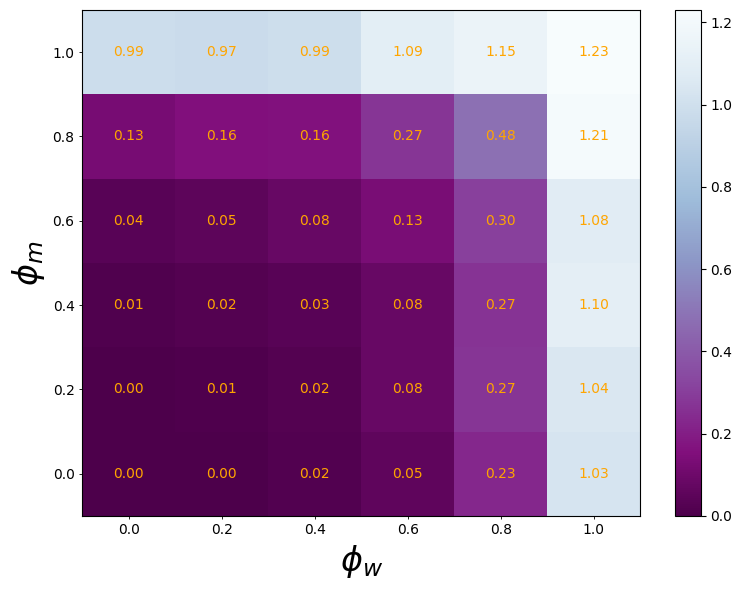

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("euclidean_mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'count_pairs']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_pairs'] = pd.to_numeric(df_filtered['count_pairs'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_pairs'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='count_pairs', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

data_matrix = data_matrix /30

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='BuPu_r', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='orange')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
#plt.title('Accomplice Manipulation: Pairs', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("euclidean_mallows_acc_pairs_30.pdf", format='pdf')
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_12247/3863260899.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['count_men'] = pd.to_numeric(df_filtered['count_men'], errors='coerce')


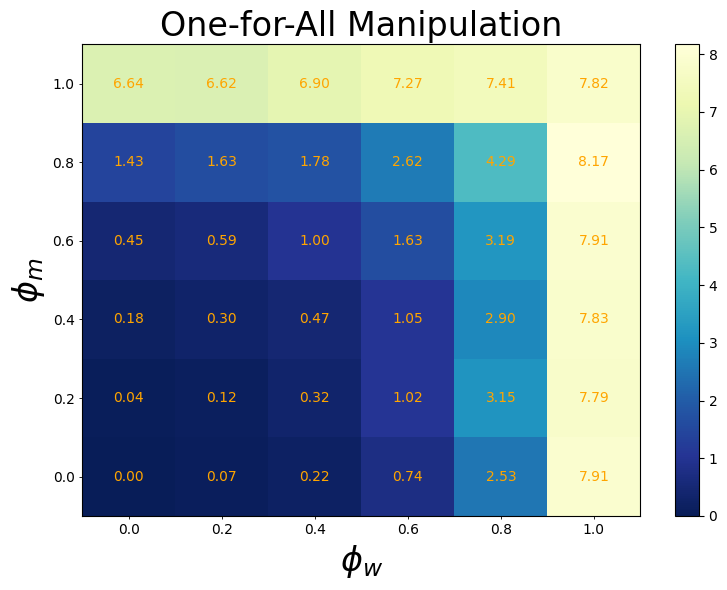

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("euclidean_mallows_accomplice.csv")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['phi_m', 'phi_w', 'count_men']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['count_men'] = pd.to_numeric(df_filtered['count_men'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['count_men'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['phi_m'].unique())
phi2_vals = sorted(df_filtered['phi_w'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='phi_m', columns='phi_w', values='count_men', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='YlGnBu_r', norm = mcolors.Normalize(vmin=np.nanmin(data_matrix), vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color='orange')

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('One-for-All Manipulation', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("euclidean_mallows_one_for_all.pdf", format='pdf')
plt.show()


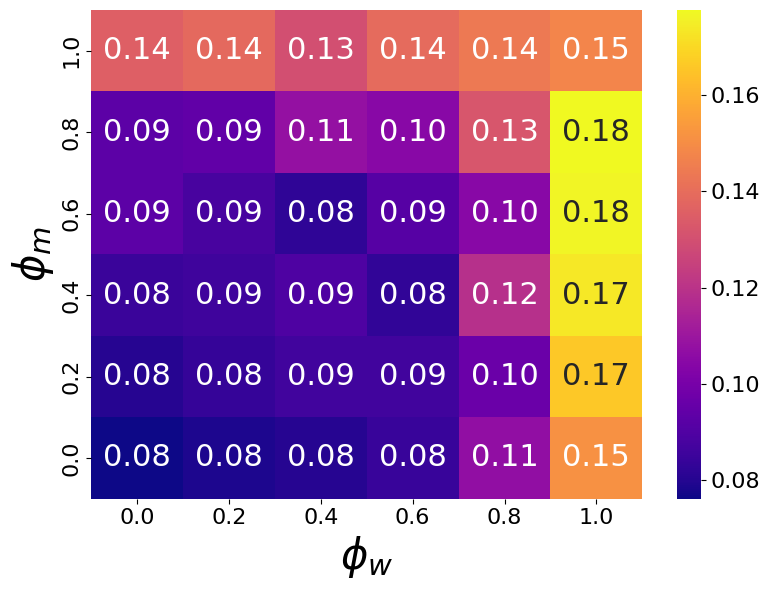

In [11]:


import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("two_for_one_results_euclidean_mallows.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["Phi1", "Phi2"])["Two_for_one"].mean().reset_index()

heatmap_data["Two_for_one"] = heatmap_data["Two_for_one"] / 900

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="Phi1", columns="Phi2", values="Two_for_one")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="plasma", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("euclidean_mallows_two_for_one_30.pdf", format="pdf")
plt.show()


/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_23638/1279591835.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')


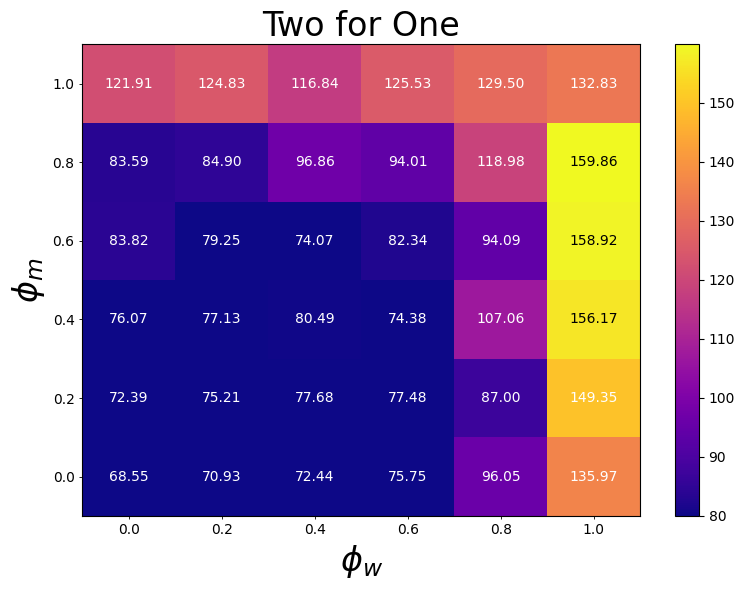

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Load the CSV with headers
df = pd.read_csv("two_for_one_results_euclidean_mallows")

# Extract relevant columns: phi1, phi2, and Two_for_one
df_filtered = df[['Phi1', 'Phi2', 'Two_for_one']]

# Convert value column to numeric in case there are stray non-numeric entries
df_filtered['Two_for_one'] = pd.to_numeric(df_filtered['Two_for_one'], errors='coerce')

# Drop any rows with invalid values
df_filtered = df_filtered.dropna(subset=['Two_for_one'])

# Get sorted unique values for heatmap axes
phi1_vals = sorted(df_filtered['Phi1'].unique())
phi2_vals = sorted(df_filtered['Phi2'].unique())

# Create pivot table (mean Two_for_one value for each (phi1, phi2) pair)
pivot_table = df_filtered.pivot_table(index='Phi1', columns='Phi2', values='Two_for_one', aggfunc='mean')

# Reindex to ensure consistent axis order
pivot_table = pivot_table.reindex(index=phi1_vals, columns=phi2_vals)

# Convert to matrix
data_matrix = pivot_table.values

# Start plotting
fig, ax = plt.subplots(figsize=(8, 6))

# Create the heatmap
c = ax.pcolormesh(data_matrix, cmap='plasma', norm=mcolors.Normalize(vmin=80, vmax=np.nanmax(data_matrix)))

# Add color bar
fig.colorbar(c, ax=ax)

# Annotate each cell
for i in range(data_matrix.shape[0]):
    for j in range(data_matrix.shape[1]):
        val = data_matrix[i, j]
        if not np.isnan(val):
            if (i == 3 and j == 5) or (i == 4 and j == 5) or (i == 2 and j == 5):
                text_color = 'black'  # Special cell
            else:
                text_color = 'white'
            ax.text(j + 0.5, i + 0.5, f'{val:.2f}', ha='center', va='center', color=text_color)

# Tick positions and labels
ax.set_xticks(np.arange(len(phi2_vals)) + 0.5, minor=True)
ax.set_yticks(np.arange(len(phi1_vals)) + 0.5, minor=True)
ax.set_xticklabels([f'{v:.1f}' for v in phi2_vals], minor=True)
ax.set_yticklabels([f'{v:.1f}' for v in phi1_vals], minor=True)

# Hide major ticks
ax.set_xticks([])
ax.set_yticks([])

# Show minor ticks only
ax.tick_params(axis='x', which='minor', bottom=True)
ax.tick_params(axis='y', which='minor', left=True)

# Labels and title
plt.xlabel(r'$\phi_w$', fontsize=24)
plt.ylabel(r'$\phi_m$', fontsize=24)
plt.title('Two for One', fontsize=24)

# Layout and save
plt.grid(True)
plt.tight_layout()
plt.savefig("euclidean_mallows_two_for_one.pdf", format='pdf')
plt.show()


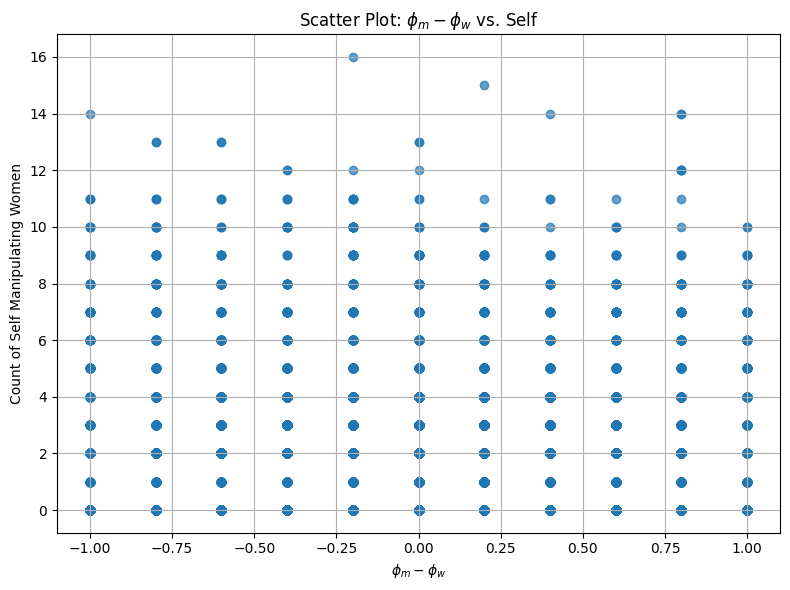

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('euclidean_mallows_accomplice.csv')

# Compute difference phi_m - phi_w
x = df['phi_m'] - df['phi_w']
y = df['self_manipulating_women']

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7)
plt.xlabel('$\phi_m - \phi_w$')
plt.ylabel('Count of Self Manipulating Women')
plt.title('Scatter Plot: $\phi_m - \phi_w$ vs. Self')
plt.grid(True)
plt.tight_layout()
plt.savefig("euclidean_mallows_scatter_plot.pdf", format='pdf')
plt.show()
